In [1]:
# imports
import pandas as pd
import numpy as np
import nfl_data_py as nfl
from xgboost import XGBClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
import matplotlib.pyplot as plt

In [2]:
# import 2025 play by play data (only the columns we need)
df = nfl.import_pbp_data([2025], columns=['game_id', 'home_team', 'away_team', 'week', 'season_type', 'posteam', 'posteam_type',
                                          'down', 'ydstogo', 'yardline_100', 'score_differential', 'game_seconds_remaining',
                                          'posteam_timeouts_remaining', 'defteam_timeouts_remaining', 'result', 'wp'])
df.columns

2025 done.
Downcasting floats.


Index(['game_id', 'home_team', 'away_team', 'week', 'season_type', 'posteam',
       'posteam_type', 'down', 'ydstogo', 'yardline_100', 'score_differential',
       'game_seconds_remaining', 'posteam_timeouts_remaining',
       'defteam_timeouts_remaining', 'result', 'wp', 'play_id',
       'old_game_id_x', 'season', 'nflverse_game_id', 'old_game_id_y',
       'possession_team', 'offense_formation', 'offense_personnel',
       'defenders_in_box', 'defense_personnel', 'number_of_pass_rushers',
       'players_on_play', 'offense_players', 'defense_players', 'n_offense',
       'n_defense', 'ngs_air_yards', 'time_to_throw', 'was_pressure', 'route',
       'defense_man_zone_type', 'defense_coverage_type', 'offense_names',
       'defense_names', 'offense_positions', 'defense_positions',
       'offense_numbers', 'defense_numbers'],
      dtype='object')

In [3]:
# preview data
df

,game_id,home_team,away_team,week,season_type,posteam,posteam_type,down,ydstogo,yardline_100,...,was_pressure,route,defense_man_zone_type,defense_coverage_type,offense_names,defense_names,offense_positions,defense_positions,offense_numbers,defense_numbers
0,2025_01_ARI_NO,NO,ARI,1,REG,None,None,NaN,0.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2025_01_ARI_NO,NO,ARI,1,REG,ARI,away,NaN,0.0,35.0,...,False,,,None,Denzel Burke;Joey Blount;Dadrion Taylor-Demers...,Rejzohn Wright;Quincy Riley;Ugo Amadi;Julian B...,CB;FS;FS;ILB;ILB;RB;S;TE;TE;TE;WR,CB;CB;FS;FS;ILB;ILB;K;MLB;OLB;RB;SS,29;32;42;44;50;31;36;84;81;87;4,25;29;0;23;53;44;19;28;40;13;33
2,2025_01_ARI_NO,NO,ARI,1,REG,ARI,away,1.0,10.0,78.0,...,False,,,None,Hjalte Froholdt;Evan Brown;Isaiah Adams;Kyler ...,Isaac Yiadom;Kool-Aid McKinstry;Nathan Shepher...,C;G;G;QB;RB;T;T;TE;TE;TE;WR,CB;CB;DT;DT;FS;ILB;MLB;NT;OLB;OLB;SS,72;63;74;1;6;73;70;85;84;87;18,27;4;93;90;23;20;56;92;94;96;21
3,2025_01_ARI_NO,NO,ARI,1,REG,ARI,away,2.0,7.0,75.0,...,False,QUICK OUT,ZONE_COVERAGE,COVER_2,Hjalte Froholdt;Evan Brown;Isaiah Adams;Kyler ...,Isaac Yiadom;Kool-Aid McKinstry;Nathan Shepher...,C;G;G;QB;RB;T;T;TE;TE;WR;WR,CB;CB;DT;DT;FS;ILB;MLB;NT;OLB;OLB;SS,72;63;74;1;6;73;70;85;87;14;18,27;4;93;90;23;20;56;92;94;96;21
4,2025_01_ARI_NO,NO,ARI,1,REG,ARI,away,1.0,10.0,64.0,...,True,,ZONE_COVERAGE,COVER_6,Hjalte Froholdt;Evan Brown;Isaiah Adams;Kyler ...,Isaac Yiadom;Kool-Aid McKinstry;Nathan Shepher...,C;G;G;QB;RB;T;T;TE;TE;WR;WR,CB;CB;DT;DT;FS;ILB;MLB;NT;OLB;OLB;SS,72;63;74;1;6;73;70;85;87;17;18,27;4;93;90;23;20;56;92;94;96;21
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48766,2025_22_SEA_NE,NE,SEA,22,POST,NE,home,1.0,5.0,67.0,...,True,GO,MAN_COVERAGE,2_MAN,Garrett Bradbury;Jack Westover;Mike Onwenu;Jar...,Riq Woolen;Josh Jobe;Devon Witherspoon;Mike Mo...,C;FB;G;G;QB;RB;T;T;WR;WR;WR,CB;CB;CB;DE;FS;ILB;NT;OLB;OLB;SS;SS,65;37;71;58;10;32;76;66;8;3;18,27;29;21;94;8;13;90;53;58;20;3
48767,2025_22_SEA_NE,NE,SEA,22,POST,NE,home,1.0,10.0,62.0,...,False,HITCH/CURL,ZONE_COVERAGE,COVER_6,Garrett Bradbury;Mike Onwenu;Jared Wilson;Drak...,Riq Woolen;Josh Jobe;Devon Witherspoon;Mike Mo...,C;G;G;QB;RB;T;T;TE;WR;WR;WR,CB;CB;CB;DE;FS;ILB;NT;OLB;OLB;SS;SS,65;71;58;10;32;76;66;81;13;9;3,27;29;21;94;8;13;90;53;58;20;3
48768,2025_22_SEA_NE,NE,SEA,22,POST,NE,home,2.0,1.0,53.0,...,False,GO,ZONE_COVERAGE,COVER_6,Garrett Bradbury;Mike Onwenu;Jared Wilson;Drak...,Riq Woolen;Josh Jobe;Devon Witherspoon;Mike Mo...,C;G;G;QB;RB;T;T;TE;WR;WR;WR,CB;CB;CB;DE;FS;ILB;NT;OLB;OLB;SS;SS,65;71;58;10;32;76;66;81;13;9;3,27;29;21;94;8;13;90;53;58;20;3
48769,2025_22_SEA_NE,NE,SEA,22,POST,NE,home,3.0,1.0,53.0,...,False,SCREEN,ZONE_COVERAGE,COVER_4,Garrett Bradbury;Mike Onwenu;Jared Wilson;Drak...,Riq Woolen;Josh Jobe;Devon Witherspoon;Byron M...,C;G;G;QB;RB;T;T;TE;WR;WR;WR,CB;CB;CB;DT;FS;ILB;NT;OLB;OLB;SS;SS,65;71;58;10;32;76;66;81;13;3;18,27;29;21;91;8;13;90;0;7;20;3


In [4]:
# Goal: predict the probability the team with the ball wins the game
# train on the regular season only (we'll save the playoffs for the end), and drop plays with missing info (kickoffs, timeouts, etc.) and tied games
playoffs = df[df['season_type'] == 'POST']
df = df[df['season_type'] == 'REG']
df = df.dropna(subset=['posteam', 'down', 'score_differential', 'result'])
df = df[df['result'] != 0]

# result = home score - away score. Did the team with the ball end up winning? (1 = yes, 0 = no)
df['win'] = np.where(df['posteam_type'] == 'home', df['result'] > 0, df['result'] < 0).astype(int)
df[['game_id', 'posteam', 'score_differential', 'game_seconds_remaining', 'win']]

,game_id,posteam,score_differential,game_seconds_remaining,win
2,2025_01_ARI_NO,ARI,0.0,3596.0,1
3,2025_01_ARI_NO,ARI,0.0,3558.0,1
4,2025_01_ARI_NO,ARI,0.0,3520.0,1
5,2025_01_ARI_NO,ARI,0.0,3477.0,1
6,2025_01_ARI_NO,ARI,0.0,3434.0,1
...,...,...,...,...,...
46446,2025_18_WAS_PHI,PHI,-7.0,53.0,0
46447,2025_18_WAS_PHI,PHI,-7.0,49.0,0
46448,2025_18_WAS_PHI,PHI,-7.0,41.0,0
46449,2025_18_WAS_PHI,PHI,-7.0,16.0,0


In [14]:
df.columns

Index(['game_id', 'home_team', 'away_team', 'week', 'season_type', 'posteam',
       'posteam_type', 'down', 'ydstogo', 'yardline_100', 'score_differential',
       'game_seconds_remaining', 'posteam_timeouts_remaining',
       'defteam_timeouts_remaining', 'result', 'wp', 'play_id',
       'old_game_id_x', 'season', 'nflverse_game_id', 'old_game_id_y',
       'possession_team', 'offense_formation', 'offense_personnel',
       'defenders_in_box', 'defense_personnel', 'number_of_pass_rushers',
       'players_on_play', 'offense_players', 'defense_players', 'n_offense',
       'n_defense', 'ngs_air_yards', 'time_to_throw', 'was_pressure', 'route',
       'defense_man_zone_type', 'defense_coverage_type', 'offense_names',
       'defense_names', 'offense_positions', 'defense_positions',
       'offense_numbers', 'defense_numbers', 'win'],
      dtype='object')

In [ ]:
# setup variables
# Why can't we use result or the final score to predict win? (we only know the situation at that moment in the game)
X = df[[]]
y = df['win']

In [6]:
# breakup training and testing data
# We split by GAME, not by play. Why? (plays from the same game share the same winner, so the model would be peeking)
games = df['game_id'].unique()
train_games, test_games = train_test_split(games, test_size=0.2, random_state=42)

X_train, y_train = X[df['game_id'].isin(train_games)], y[df['game_id'].isin(train_games)]
X_test, y_test = X[df['game_id'].isin(test_games)], y[df['game_id'].isin(test_games)]

In [7]:
# Baseline: one decision tree (what we built last time)
tree = DecisionTreeClassifier(max_depth=3, random_state=42)
tree.fit(X_train, y_train)

print("Decision Tree Accuracy:", accuracy_score(y_test, tree.predict(X_test)))

Decision Tree Accuracy: 0.713377449072272


In [8]:
# XGBoost = lots of small trees built one after another
# tree 1 makes a guess, tree 2 tries to fix tree 1's mistakes, tree 3 fixes what's left, ...
# n_estimators  = how many trees
# max_depth     = how big each tree is (keep them small)
# learning_rate = how much each new tree is allowed to change the prediction
model = XGBClassifier(n_estimators=100, max_depth=3, learning_rate=0.1, random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("XGBoost Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n ", classification_report(y_test, y_pred))

XGBoost Accuracy: 0.718697288179577

Classification Report:
                precision    recall  f1-score   support

           0       0.73      0.66      0.70      3744
           1       0.71      0.77      0.74      3963

    accuracy                           0.72      7707
   macro avg       0.72      0.72      0.72      7707
weighted avg       0.72      0.72      0.72      7707



In [9]:
# Did it overfit? Compare accuracy on plays it has seen vs plays it hasn't
print("Train Accuracy:", accuracy_score(y_train, model.predict(X_train)))
print("Test Accuracy: ", accuracy_score(y_test, y_pred))

Train Accuracy: 0.7408125040366854
Test Accuracy:  0.718697288179577


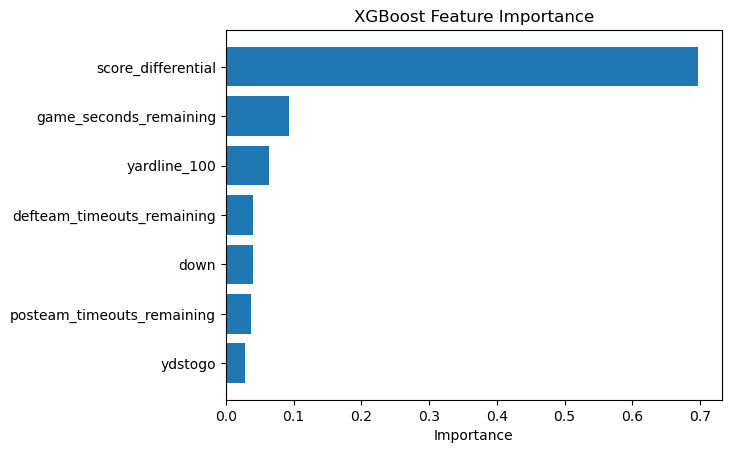

In [10]:
# Which stats did the model lean on the most? Does this make sense for predicting a winner?
importance = pd.Series(model.feature_importances_, index=X.columns).sort_values()

plt.barh(importance.index, importance.values)
plt.xlabel('Importance')
plt.title('XGBoost Feature Importance')
plt.show()

In [ ]:
# Unlike the decision tree, XGBoost gives us a probability, not just a 1 or 0
# Same down and distance, but how does win probability change with the score and time left?
situations = pd.DataFrame({
    'score_differential': [0, 7, 7, -7, 14],
    'game_seconds_remaining': [3600, 3600, 300, 300, 120],
    'down': [1, 1, 1, 1, 1], 
    'ydstogo': [10, 10, 10, 10, 10],
    'yardline_100': [75, 75, 75, 75, 75],
    'posteam_timeouts_remaining': [3, 3, 3, 3, 3],
    'defteam_timeouts_remaining': [3, 3, 3, 3, 3]
})
situations['win_prob'] = model.predict_proba(situations[X.columns])[:, 1].round(2)
situations

,score_differential,game_seconds_remaining,down,ydstogo,yardline_100,posteam_timeouts_remaining,defteam_timeouts_remaining,win_prob
0,0,3600,1,10,75,3,3,0.46
1,7,3600,1,10,75,3,3,0.68
2,7,300,1,10,75,3,3,0.88
3,-7,300,1,10,75,3,3,0.24
4,14,120,1,10,75,3,3,0.95


In [12]:
# Bonus: nflfastR has a win probability model built from many seasons of data and more variables (wp column)
# How does our model, trained on only 2025, compare?
test_plays = df[df['game_id'].isin(test_games)]

print("XGBoost Accuracy:", accuracy_score(y_test, y_pred))
print("nflfastR Accuracy:", accuracy_score(test_plays['win'], test_plays['wp'] > 0.5))

XGBoost Accuracy: 0.718697288179577
nflfastR Accuracy: 0.7215518359932529


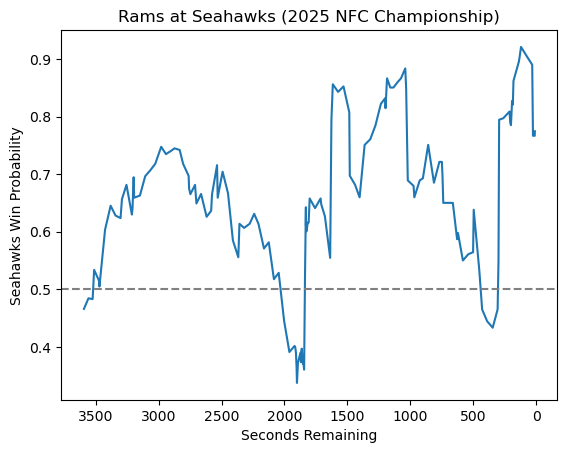

In [13]:
# Last year's NFC Championship: Rams at Seahawks. Our model only learned from the regular season, so it has never seen this game
game = playoffs[playoffs['game_id'] == '2025_21_LA_SEA']
game = game.dropna(subset=['posteam', 'down', 'score_differential']).copy()

# flip to the home team's point of view so the line doesn't jump around when possession changes
prob = model.predict_proba(game[X.columns])[:, 1]
game['home_win_prob'] = np.where(game['posteam_type'] == 'home', prob, 1 - prob)

plt.plot(game['game_seconds_remaining'], game['home_win_prob'])
plt.axhline(0.5, color='gray', linestyle='--')
plt.gca().invert_xaxis()  # time counts down
plt.xlabel('Seconds Remaining')
plt.ylabel('Seahawks Win Probability')
plt.title('Rams at Seahawks (2025 NFC Championship)')
plt.show()